<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 6: The Art of Value – Pricing Strategy & Marketing

**Topic:** Marketing Economics, Price Discrimination, and Dynamic Pricing Algorithms.

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu  
**ID:** 6888143

---

### **1. Introduction: Pricing is an Algorithm**

In traditional economics, we often assume a single "Market Price." In the real world, companies use complex algorithms to capture more value.

**Marketing** in economics isn't just advertising; it's about signaling value and shifting the Demand Curve.
**Pricing Strategy** is about capturing the area under that curve.

Today, we will simulate two powerful strategies:
1.  **Price Discrimination:** Charging different prices to different people (e.g., Student Discounts).
2.  **Dynamic Pricing:** Changing prices in real-time based on supply/demand (e.g., Uber Surge, Hotel Booking).

These are the algorithms that power modern tech platforms.

In [5]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. Strategy 1: Price Discrimination (The Cinema Model)**

Why do cinemas offer "Student Tickets"?

* **Adults:** High income, Inelastic demand (Will pay $15).
* **Students:** Low income, Elastic demand (Will pay \\$10, but not \\$15).

If the cinema charges **$12**:

* Adults pay (Revenue = \\$12), but the cinema loses the \\$3 surplus the adult would have paid.
* Students don't go (Revenue = $0).

If the cinema **Discriminates** (Adult=\\$15, Student=\\$10), it captures BOTH markets fully.

Let's simulate this.

In [6]:
def price_discrimination_sim(adult_price, student_price):
    # --- Market Parameters ---
    # Demand Function: Q = Intercept - Slope * Price
    
    # Adults: High willingness to pay
    adult_intercept = 100
    adult_slope = 2
    
    # Students: Lower willingness to pay, more sensitive
    student_intercept = 80
    student_slope = 4
    
    # --- Calculate Quantities ---
    q_adult = max(0, adult_intercept - adult_slope * adult_price)
    q_student = max(0, student_intercept - student_slope * student_price)
    
    # --- Calculate Revenue ---
    rev_adult = q_adult * adult_price
    rev_student = q_student * student_price
    total_rev = rev_adult + rev_student
    
    # --- Calculate Single Price Benchmark (If we forced everyone to pay Adult Price) ---
    # In a single price world, price usually settles somewhere in between
    # Let's assume the single price would be $12
    single_price = 12
    q_adult_single = max(0, adult_intercept - adult_slope * single_price)
    q_student_single = max(0, student_intercept - student_slope * single_price)
    rev_single_strat = (q_adult_single + q_student_single) * single_price
    
    # --- Visualization ---
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Bar Chart comparison
    strategies = ['Single Price Strategy ($12)', 'Dual Price Strategy (Your Input)']
    revenues = [rev_single_strat, total_rev]
    
    bars = ax.bar(strategies, revenues, color=['gray', 'green'])
    ax.set_ylabel('Total Revenue ($)')
    ax.set_title(f'Revenue Comparison: Strategy Wins by ${total_rev - rev_single_strat:.0f}')
    ax.bar_label(bars, fmt='${:,.0f}')
    
    print(f"--- SEGMENT BREAKDOWN ---")
    print(f"Adults:   Price ${adult_price} -> Qty {q_adult:.0f} -> Rev ${rev_adult:.0f}")
    print(f"Students: Price ${student_price} -> Qty {q_student:.0f} -> Rev ${rev_student:.0f}")
    print(f"Total Revenue: ${total_rev:.0f}")
    
    plt.show()

# Interactive Widget
style = {'description_width': 'initial'}
widgets.interactive(price_discrimination_sim,
    adult_price=widgets.IntSlider(min=0, max=50, value=25, description='Adult Price ($)', style=style),
    student_price=widgets.IntSlider(min=0, max=50, value=10, description='Student Price ($)', style=style)
)

interactive(children=(IntSlider(value=25, description='Adult Price ($)', max=50, style=SliderStyle(description…

### **3. Strategy 2: Dynamic Pricing (The Hotel Model)**

Fixed prices fail because demand fluctuates over time. 
* **Inventory:** 100 Hotel Rooms.
* **Goal:** Sell all rooms by day 0 at the highest possible price.
* **Constraint:** Unsold rooms have a value of $0 (Perishable inventory).

We will code a simple algorithm:
> *If inventory is too high for the time remaining $\to$ Lower Price.*
> *If inventory is selling too fast $\to$ Raise Price.*

In [7]:
def dynamic_pricing_algorithm(base_price=100, demand_sensitivity=2, use_algorithm=True):
    # Simulation Parameters
    days = 30
    total_rooms = 150
    
    # Tracking Lists
    inventory_history = [total_rooms]
    price_history = []
    revenue_history = []
    revenue_cumulative = 0
    
    current_inventory = total_rooms
    
    # Loop through each day (Day 30 down to Day 1)
    for day_remaining in range(days, 0, -1):
        
        # --- PRICING LOGIC ---
        if use_algorithm:
            # Ideal Inventory Pace: We want to sell evenly over time
            ideal_inventory = (day_remaining / days) * total_rooms
            
            # If we have MORE rooms than ideal, we are behind schedule -> Lower Price
            # If we have FEWER rooms than ideal, we are ahead -> Raise Price
            inventory_gap = current_inventory - ideal_inventory
            
            # Adjustment Factor: $2 for every room off-pace
            price_adjustment = -2 * inventory_gap
            current_price = max(50, base_price + price_adjustment) # Minimum price floor $50
        else:
            # Static Pricing
            current_price = base_price
            
        # --- DEMAND SIMULATION ---
        # Demand is random but lower prices attract more buyers
        # Base demand + Price effect + Random noise
        daily_demand = 10 - (demand_sensitivity * (current_price - 100)/10) + np.random.randint(-2, 3)
        daily_sales = min(current_inventory, max(0, int(daily_demand)))
        
        # Update State
        current_inventory -= daily_sales
        daily_revenue = daily_sales * current_price
        revenue_cumulative += daily_revenue
        
        # Record Data
        inventory_history.append(current_inventory)
        price_history.append(current_price)
        revenue_history.append(revenue_cumulative)

    # --- VISUALIZATION ---
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    # Plot 1: Inventory & Sales
    ax1.plot(range(days, -1, -1), inventory_history, marker='o', label='Remaining Rooms')
    ax1.plot([days, 0], [total_rooms, 0], 'r--', label='Ideal Pace', alpha=0.5)
    ax1.set_ylabel('Inventory')
    ax1.set_title(f'Booking Curve (Total Revenue: ${revenue_cumulative:,.0f})')
    ax1.legend()
    ax1.invert_xaxis() # Count down from 30 to 0
    
    # Plot 2: Price Fluctuation
    ax2.step(range(days, 0, -1), price_history, color='green', where='post')
    ax2.set_ylabel('Price ($)')
    ax2.set_xlabel('Days Remaining')
    ax2.set_title('Dynamic Price Adjustments')
    
    plt.show()
    print(f"Final Unsold Inventory: {current_inventory} rooms")

widgets.interactive(dynamic_pricing_algorithm,
    base_price=widgets.IntSlider(min=80, max=150, value=100, description='Base Price'),
    use_algorithm=widgets.Checkbox(value=True, description='Enable Dynamic Pricing Algorithm')
)

interactive(children=(IntSlider(value=100, description='Base Price', max=150, min=80), IntSlider(value=2, desc…

### **4. Case Study: Uber Surge Pricing (Real Data)**

Uber uses dynamic pricing to balance supply (drivers) and demand (riders).
We will look at a sample dataset (Cab rides) to see how price per mile changes based on Time and Weather.

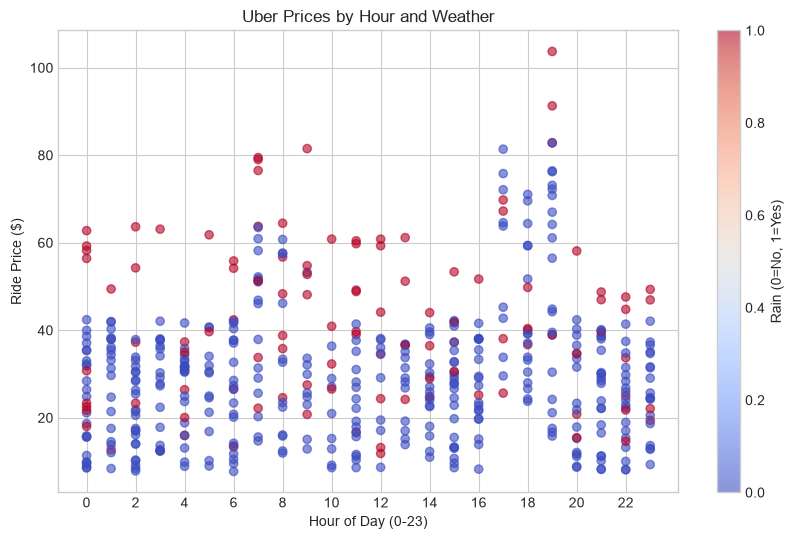

In [8]:
# Synthetic Uber Data Generation
np.random.seed(42)
n_rides = 500

# Variables
hours = np.random.randint(0, 24, n_rides)
is_raining = np.random.choice([0, 1], n_rides, p=[0.8, 0.2]) # 20% chance of rain
base_fare = 5.0
distance_miles = np.random.uniform(1, 15, n_rides)

# Pricing Algorithm Model
multiplier = np.ones(n_rides)

# 1. Rush Hour Surge (7-9 AM, 5-7 PM)
multiplier = np.where((hours >= 7) & (hours <= 9), 1.5, multiplier)
multiplier = np.where((hours >= 17) & (hours <= 19), 2.0, multiplier)

# 2. Rain Surge
multiplier = np.where(is_raining == 1, multiplier + 0.5, multiplier)

# Final Price
final_price = (base_fare + (distance_miles * 2.5)) * multiplier

df_uber = pd.DataFrame({
    'Hour': hours,
    'Rain': is_raining,
    'Distance': distance_miles,
    'Surge_Multiplier': multiplier,
    'Price': final_price
})

# Visualization
plt.figure(figsize=(10, 6))
plt.scatter(df_uber['Hour'], df_uber['Price'], c=df_uber['Rain'], cmap='coolwarm', alpha=0.6)
plt.colorbar(label='Rain (0=No, 1=Yes)')
plt.title('Uber Prices by Hour and Weather')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Ride Price ($)')
plt.xticks(range(0, 24, 2))
plt.grid(True)
plt.show()

---
## **5. Homework Assignment**

**Objective:** Analyze the impact of algorithmic pricing.

#### **Question 1: The Static vs. Dynamic Test**
Go back to the **Section 3 (Hotel)** simulator.
1.  Run the simulation **WITH** the algorithm enabled. Record the `Total Revenue` and `Final Unsold Inventory`.
    Change the base price to 121, keep demand_sensitivity the same, the Total Revenue: $18,438, and the Final Unsold Inventory: 0.
2.  Uncheck the box to **DISABLE** the algorithm (Static Pricing). Record the results.
    16rooms left and the total Revenue: $16,940, if change the base price to 100, there will be not room left, but the Total Revenue will decrese to $15,000
3.  **Analysis:** Why did the static strategy likely leave rooms empty (unsold inventory) or sell out too early (leaving money on the table)?
    if the price is low, more people willing to pay, wihch means the demand suppresses the supply.

#### **Question 2: Business Transaction Analysis**
Think of a purchase you made recently (Coffee, Grab/Uber, Airline Ticket, Shopee).
* Did the seller use **Price Discrimination** (e.g., Member discount, Coupon)?
    Yes, free shipping coupon, it requires you to purchase the minimal price
* Did they use **Bundling** (e.g., Fries + Burger)?
    Not for this one
* Did they use **Psychological Pricing** (e.g., 99 baht)?
    Yes, the price is 189 with free shipping
* **Task:** Identify the strategy and explain how it influenced your decision (did it increase your Willingness to Pay?).
    If one owner's price is low but has extra shipping fee, and the another one has no shipping fee but the price is higher, normally I will think the shipping fee is unnecessary even though the first's total price is still cheaper.
*(Write your answers in the Markdown cell below)*

### **Student Answers Space**

**Q1 Analysis:**
1.  Run the simulation **WITH** the algorithm enabled. Record the `Total Revenue` and `Final Unsold Inventory`.
    
    Change the base price to 121, keep demand_sensitivity the same, the Total Revenue: *$18,438*, and the Final Unsold Inventory: *0*.
2.  Uncheck the box to **DISABLE** the algorithm (Static Pricing). Record the results.
    
    16rooms left and the total Revenue: *$16,940*, if change the base price to *100*, there will be not room left, but the Total Revenue will decrese to *$15,000*
3.  **Analysis:** Why did the static strategy likely leave rooms empty (unsold inventory) or sell out too early (leaving money on the table)?
    
    if the price is low, more people willing to pay, wihch means the demand suppresses the supply.

**Q2 Analysis:**
* Did the seller use **Price Discrimination** (e.g., Member discount, Coupon)?
    
    1. Yes, free shipping coupon, it requires you to purchase the minimal price
* Did they use **Bundling** (e.g., Fries + Burger)?
    
    2. Not for this one
* Did they use **Psychological Pricing** (e.g., 99 baht)?
   
    3. Yes, the price is 189 with free shipping
* **Task:** Identify the strategy and explain how it influenced your decision (did it increase your Willingness to Pay?).
    
    4. If one owner's price is low but has extra shipping fee, and the another one has no shipping fee but the price is higher, normally I will think the shipping fee is unnecessary even though the first's total price is still cheaper.
